# Support Vector Regression for Clinical Applications

## Clinical AI Workshop Series - Part 5B

**Learning Objectives:**
- Understand how SVR predicts continuous values
- Learn about epsilon tubes and support vectors in regression
- Apply SVR to drug plasma concentration prediction
- Compare linear vs non-linear SVR models
- Understand when to use SVR vs other regression methods

**Duration:** ~25 minutes

---

Support Vector Regression (SVR) extends SVM to predict continuous values. Instead of finding boundaries between classes, SVR finds a **tube** that contains most training points.

In this notebook, we'll apply SVR to **drug plasma concentration prediction** - estimating how much drug is circulating in a patient's blood at a given time after a dose, from the patient's age, weight, renal function and the dose given. This is the core question behind therapeutic drug monitoring and individualized dosing.

> **About the data.** Every patient in this notebook is simulated from a published
> pharmacokinetic model and standard physiological reference ranges. No real or
> identifiable patient data is used.


In [1]:
# Essential imports for clinical SVR analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('default')
sns.set_palette("husl")
np.random.seed(42)

print("💊 Clinical Support Vector Regression: Ready for Pharmacokinetic Analysis")
print("   This notebook demonstrates continuous value prediction for therapeutic drug monitoring")


💊 Clinical Support Vector Regression: Ready for Pharmacokinetic Analysis
   This notebook demonstrates continuous value prediction for therapeutic drug monitoring


## 1. Drug Plasma Concentration Dataset

We'll create a realistic dataset simulating therapeutic drug monitoring samples:

**Input Features:**
- Hours since dose - Time elapsed since the tablet was taken
- Age (years) - Older patients absorb more slowly
- Weight (kg) - Drives the volume of distribution
- eGFR (mL/min/1.73 m2) - Renal function, drives clearance
- Dose (mg) - Amount of drug given

**Target:**
- Plasma concentration (mg/L) at the time the blood sample was drawn

### The pharmacokinetic model behind the data

The concentration follows a **one-compartment model with first-order absorption and
first-order elimination**:

$$C(t) = \frac{F \cdot D \cdot k_a}{V_d \cdot (k_a - k_e)} \left( e^{-k_e t} - e^{-k_a t} \right)$$

where $F$ is bioavailability, $D$ the dose, $k_a$ the absorption rate constant,
$V_d$ the volume of distribution (scaling with body weight) and
$k_e = CL / V_d$ the elimination rate constant (clearance $CL$ scaling with eGFR).

That curve **rises steeply, peaks, then decays** - two exponentials pulling in opposite
directions. It is exactly the kind of shape a straight line cannot follow, which is why
it makes such a good demonstration of what an RBF kernel buys you.


In [2]:
def generate_plasma_concentration_data(n_samples=1000):
    """
    Generate synthetic but realistic drug plasma concentration data.

    One-compartment pharmacokinetic model with first-order absorption and
    first-order elimination:

        C(t) = (F * D * ka) / (Vd * (ka - ke)) * (exp(-ke*t) - exp(-ka*t))

    Population variability enters through three patient covariates:
      * Volume of distribution scales with body weight (Vd = 0.60 * weight)
      * Clearance scales with renal function (CL proportional to eGFR),
        so the elimination constant is ke = CL / Vd
      * Absorption slows modestly with age (slower gastric emptying)

    All values are simulated. No real patient data is used.
    """
    np.random.seed(42)

    # --- Sampling design -------------------------------------------------
    # Therapeutic drug monitoring samples cluster early after the dose, when
    # the concentration is changing fastest, then thin out over the day.
    hours_since_dose = 0.25 + 23.75 * np.random.beta(1.3, 2.0, n_samples)

    # --- Patient covariates ----------------------------------------------
    age = np.random.uniform(18, 90, n_samples)                            # years
    weight_kg = np.clip(np.random.normal(78, 15, n_samples), 40, 150)     # kg
    egfr = np.clip(np.random.normal(80, 25, n_samples), 15, 130)          # mL/min/1.73m2
    dose_mg = np.random.choice([100, 150, 200, 250, 300], n_samples)      # mg

    # --- Pharmacokinetic parameters --------------------------------------
    bioavailability = 0.75                       # fraction of the dose absorbed

    # Volume of distribution scales with body size (litres)
    vd = 0.60 * weight_kg

    # Absorption rate constant, per hour. Gastric emptying slows with age.
    ka = np.clip(1.20 - 0.004 * (age - 50), 0.45, 1.80)

    # Clearance (litres per hour) is driven by renal function
    clearance = 4.5 * (egfr / 90.0)

    # Elimination rate constant, per hour. Poor renal function means a small
    # ke, a long half-life, and drug that accumulates.
    ke = np.clip(clearance / vd, 0.005, ka - 0.05)

    # --- The concentration-time curve ------------------------------------
    # Two competing exponentials: absorption in, elimination out.
    plasma_conc = (
        (bioavailability * dose_mg * ka) / (vd * (ka - ke))
        * (np.exp(-ke * hours_since_dose) - np.exp(-ka * hours_since_dose))
    )

    # Assay variability: proportional (immunoassay error) plus a small
    # additive term near the limit of quantification
    plasma_conc = (
        plasma_conc * np.exp(np.random.normal(0, 0.08, n_samples))
        + np.random.normal(0, 0.02, n_samples)
    )

    # Keep every value inside a measurable, plausible range
    plasma_conc = np.clip(plasma_conc, 0.01, 15.0)

    # Create DataFrame
    data = pd.DataFrame({
        'hours_since_dose': hours_since_dose,
        'age': age,
        'weight_kg': weight_kg,
        'egfr': egfr,
        'dose_mg': dose_mg,
        'plasma_conc_mg_l': plasma_conc
    })

    return data

# Generate dataset
pk_data = generate_plasma_concentration_data(1000)

print("💊 Plasma Concentration Dataset Generated (simulated, no real patient data)")
print(f"   Total samples: {len(pk_data)}")
print(f"   Concentration range: {pk_data['plasma_conc_mg_l'].min():.2f} to {pk_data['plasma_conc_mg_l'].max():.2f} mg/L")

# Display statistics
print("\n📊 Dataset Statistics:")
pk_data.describe().round(2)


💊 Plasma Concentration Dataset Generated (simulated, no real patient data)
   Total samples: 1000
   Concentration range: 0.09 to 6.09 mg/L

📊 Dataset Statistics:


,hours_since_dose,age,weight_kg,egfr,dose_mg,plasma_conc_mg_l
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,9.54,53.75,77.74,79.25,206.45,1.74
std,5.54,20.79,14.66,24.67,71.32,1.05
min,0.29,18.02,40.00,15.00,100.00,0.09
25%,5.00,36.50,67.80,63.36,150.00,0.96
50%,8.96,52.65,77.86,78.94,200.00,1.52
75%,13.65,71.65,87.89,97.00,250.00,2.39
max,23.32,89.91,124.69,130.00,300.00,6.09


## 2. Visualizing Concentration Patterns

Let's explore how plasma concentration varies with the main pharmacokinetic drivers.


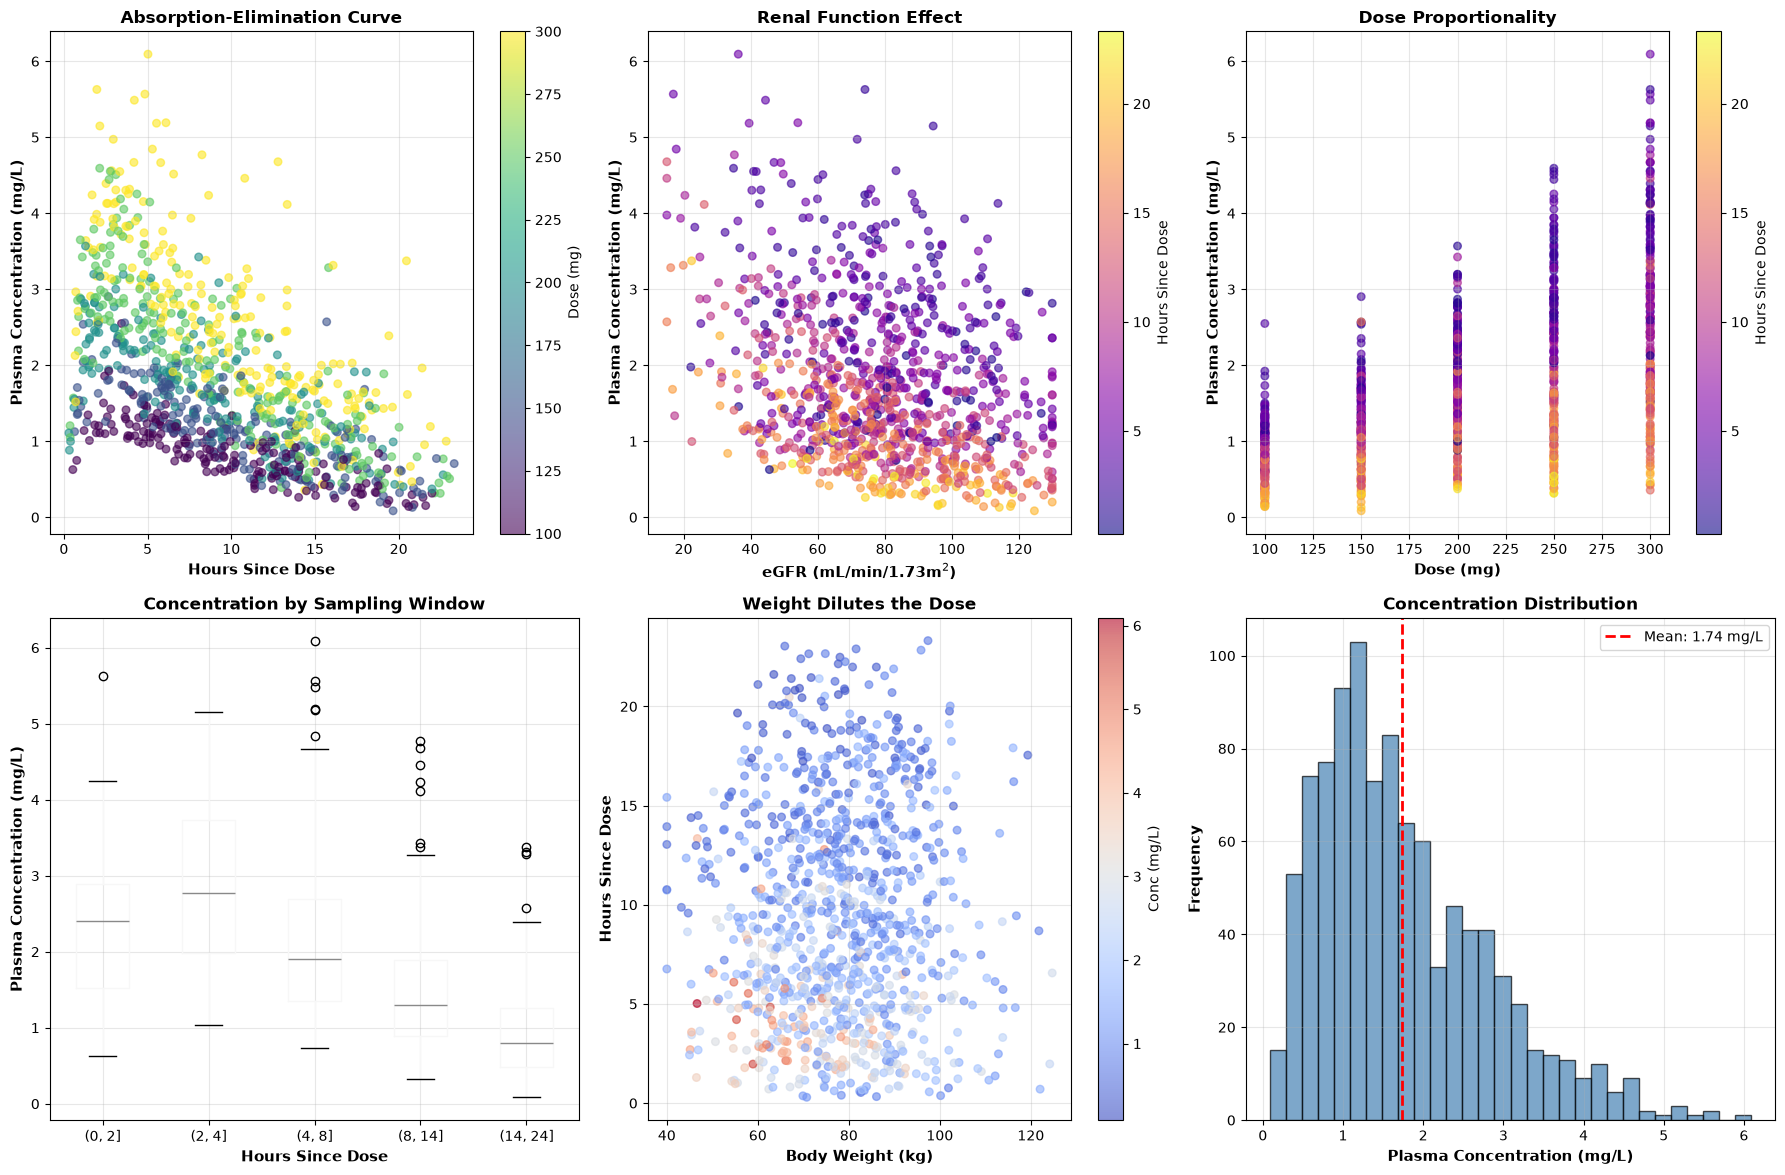


🔍 Pharmacokinetic Observations:
   • Concentration rises steeply, peaks around 2-4 hours, then decays
   • Poor renal function (low eGFR) means slower clearance and higher levels
   • Concentration scales with dose, but the curve shape does not
   • Complex non-linear relationships → SVR is ideal!


In [3]:
# Create comprehensive visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Plasma Concentration Patterns - Pharmacokinetic Relationships',
             fontsize=16, fontweight='bold')

# Plot 1: Concentration vs Time Since Dose (the absorption-elimination curve)
ax = axes[0, 0]
scatter = ax.scatter(pk_data['hours_since_dose'], pk_data['plasma_conc_mg_l'],
                    c=pk_data['dose_mg'], cmap='viridis',
                    alpha=0.6, s=30)
ax.set_xlabel('Hours Since Dose', fontsize=11, fontweight='bold')
ax.set_ylabel('Plasma Concentration (mg/L)', fontsize=11, fontweight='bold')
ax.set_title('Absorption-Elimination Curve', fontweight='bold')
ax.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax, label='Dose (mg)')

# Plot 2: Concentration vs Renal Function
ax = axes[0, 1]
scatter = ax.scatter(pk_data['egfr'], pk_data['plasma_conc_mg_l'],
                    c=pk_data['hours_since_dose'], cmap='plasma',
                    alpha=0.6, s=30)
ax.set_xlabel('eGFR (mL/min/1.73m$^2$)', fontsize=11, fontweight='bold')
ax.set_ylabel('Plasma Concentration (mg/L)', fontsize=11, fontweight='bold')
ax.set_title('Renal Function Effect', fontweight='bold')
ax.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax, label='Hours Since Dose')

# Plot 3: Concentration vs Dose
ax = axes[0, 2]
scatter = ax.scatter(pk_data['dose_mg'], pk_data['plasma_conc_mg_l'],
                    c=pk_data['hours_since_dose'], cmap='plasma',
                    alpha=0.6, s=30)
ax.set_xlabel('Dose (mg)', fontsize=11, fontweight='bold')
ax.set_ylabel('Plasma Concentration (mg/L)', fontsize=11, fontweight='bold')
ax.set_title('Dose Proportionality', fontweight='bold')
ax.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax, label='Hours Since Dose')

# Plot 4: Concentration distribution by time window
ax = axes[1, 0]
time_bins = [0, 2, 4, 8, 14, 24]
pk_data['time_window'] = pd.cut(pk_data['hours_since_dose'], bins=time_bins)
pk_data.boxplot(column='plasma_conc_mg_l', by='time_window', ax=ax)
ax.set_xlabel('Hours Since Dose', fontsize=11, fontweight='bold')
ax.set_ylabel('Plasma Concentration (mg/L)', fontsize=11, fontweight='bold')
ax.set_title('Concentration by Sampling Window', fontweight='bold')
plt.suptitle('')  # Remove default title
ax.grid(True, alpha=0.3)

# Plot 5: Body weight vs time, coloured by concentration
ax = axes[1, 1]
scatter = ax.scatter(pk_data['weight_kg'], pk_data['hours_since_dose'],
                    c=pk_data['plasma_conc_mg_l'], cmap='coolwarm',
                    alpha=0.6, s=30)
ax.set_xlabel('Body Weight (kg)', fontsize=11, fontweight='bold')
ax.set_ylabel('Hours Since Dose', fontsize=11, fontweight='bold')
ax.set_title('Weight Dilutes the Dose', fontweight='bold')
ax.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax, label='Conc (mg/L)')

# Plot 6: Concentration distribution
ax = axes[1, 2]
ax.hist(pk_data['plasma_conc_mg_l'], bins=30, alpha=0.7,
        color='steelblue', edgecolor='black')
ax.set_xlabel('Plasma Concentration (mg/L)', fontsize=11, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=11, fontweight='bold')
ax.set_title('Concentration Distribution', fontweight='bold')
ax.axvline(pk_data['plasma_conc_mg_l'].mean(), color='red',
          linestyle='--', linewidth=2, label=f'Mean: {pk_data["plasma_conc_mg_l"].mean():.2f} mg/L')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n🔍 Pharmacokinetic Observations:")
print("   • Concentration rises steeply, peaks around 2-4 hours, then decays")
print("   • Poor renal function (low eGFR) means slower clearance and higher levels")
print("   • Concentration scales with dose, but the curve shape does not")
print("   • Complex non-linear relationships → SVR is ideal!")


## 3. How SVR Works: Epsilon-Tube Regression

Unlike linear regression that minimizes all errors, SVR creates an **epsilon tube** around predictions:

**Key Concepts:**
1. **Epsilon (ε)**: Width of the tube (tolerance)
2. **Support Vectors**: Points outside the tube
3. **C**: Penalty for points outside the tube
4. **Kernel**: Transform for non-linear relationships

Let's start with a simple 1D example!

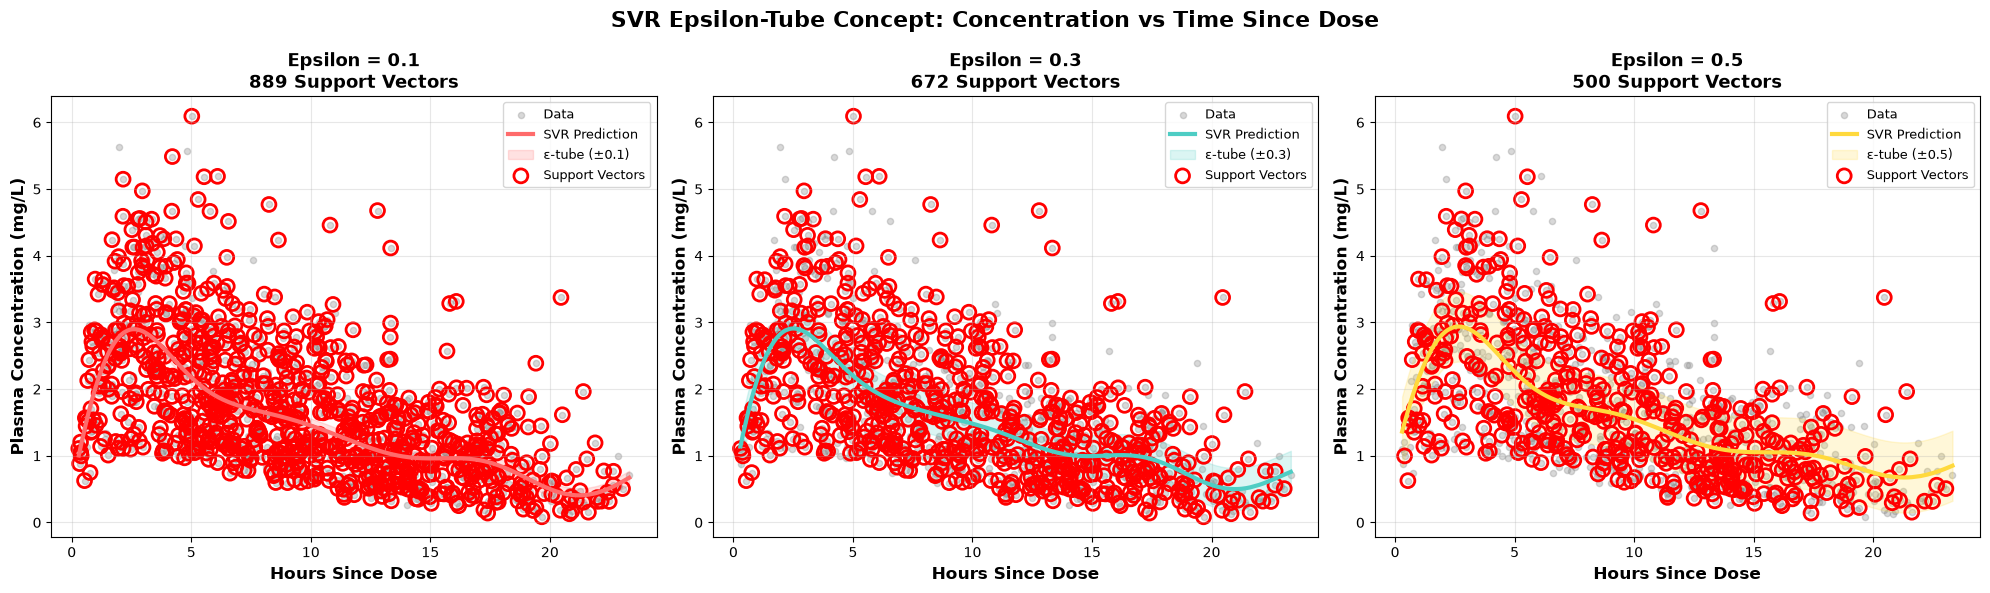


💡 Understanding Epsilon:
   • Small ε (0.1): Narrow tube, many support vectors, fits data closely
   • Medium ε (0.3): Balanced tube, moderate support vectors
   • Large ε (0.5): Wide tube, few support vectors, smooth prediction

   Red circles = Support Vectors (points outside the tube)
   Only these points affect the model!


In [4]:
# Simple 1D example: Concentration vs Time Since Dose
# Extract and sort for visualization
hours_1d = pk_data['hours_since_dose'].values.reshape(-1, 1)
conc_1d = pk_data['plasma_conc_mg_l'].values

# Sort for clean plotting
sort_idx = np.argsort(hours_1d.flatten())
hours_sorted = hours_1d[sort_idx]
conc_sorted = conc_1d[sort_idx]

# Scale the data
scaler_x = StandardScaler()
scaler_y = StandardScaler()
hours_scaled = scaler_x.fit_transform(hours_sorted)
conc_scaled = scaler_y.fit_transform(conc_sorted.reshape(-1, 1)).flatten()

# Train SVR with different epsilon values
epsilons = [0.1, 0.3, 0.5]
colors = ['#FF6B6B', '#4ECDC4', '#FFD93D']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('SVR Epsilon-Tube Concept: Concentration vs Time Since Dose',
             fontsize=16, fontweight='bold')

for idx, (eps, color) in enumerate(zip(epsilons, colors)):
    ax = axes[idx]

    # Train SVR
    svr = SVR(kernel='rbf', epsilon=eps, C=100, gamma='scale')
    svr.fit(hours_scaled, conc_scaled)

    # Predict
    conc_pred = svr.predict(hours_scaled)

    # Plot
    ax.scatter(hours_sorted, conc_sorted, alpha=0.3, s=20, c='gray', label='Data')
    ax.plot(hours_sorted, scaler_y.inverse_transform(conc_pred.reshape(-1, 1)),
            color=color, linewidth=3, label='SVR Prediction')

    # Plot epsilon tube
    conc_pred_original = scaler_y.inverse_transform(conc_pred.reshape(-1, 1)).flatten()
    eps_original = eps * scaler_y.scale_[0]  # Scale epsilon to original units
    ax.fill_between(hours_sorted.flatten(),
                    conc_pred_original - eps_original,
                    conc_pred_original + eps_original,
                    alpha=0.2, color=color, label=f'ε-tube (±{eps})')

    # Highlight support vectors
    support_mask = np.zeros(len(hours_scaled), dtype=bool)
    support_mask[svr.support_] = True
    support_mask_sorted = support_mask[sort_idx]
    ax.scatter(hours_sorted[support_mask_sorted],
              conc_sorted[support_mask_sorted],
              s=100, facecolors='none', edgecolors='red',
              linewidths=2, label='Support Vectors')

    ax.set_xlabel('Hours Since Dose', fontsize=12, fontweight='bold')
    ax.set_ylabel('Plasma Concentration (mg/L)', fontsize=12, fontweight='bold')
    ax.set_title(f'Epsilon = {eps}\n{len(svr.support_)} Support Vectors',
                fontweight='bold', fontsize=13)
    ax.legend(loc='best', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 Understanding Epsilon:")
print("   • Small ε (0.1): Narrow tube, many support vectors, fits data closely")
print("   • Medium ε (0.3): Balanced tube, moderate support vectors")
print("   • Large ε (0.5): Wide tube, few support vectors, smooth prediction")
print("\n   Red circles = Support Vectors (points outside the tube)")
print("   Only these points affect the model!")


## 4. Training SVR for Plasma Concentration Prediction

Now let's train a full SVR model using all features.


In [5]:
# Prepare data
X = pk_data[['hours_since_dose', 'age', 'weight_kg', 'egfr', 'dose_mg']]
y = pk_data['plasma_conc_mg_l']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features (CRITICAL for SVR!)
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).flatten()

print("📊 Data Preparation Complete")
print(f"   Training samples: {len(X_train)}")
print(f"   Testing samples: {len(X_test)}")
print(f"   Features: {list(X.columns)}")

# Train Linear SVR
print("\n🔵 Training Linear SVR...")
svr_linear = SVR(kernel='linear', C=1.0, epsilon=0.1)
svr_linear.fit(X_train_scaled, y_train_scaled)

y_pred_linear = svr_linear.predict(X_test_scaled)
y_pred_linear_original = scaler_y.inverse_transform(y_pred_linear.reshape(-1, 1)).flatten()

# Metrics
mse_linear = mean_squared_error(y_test, y_pred_linear_original)
rmse_linear = np.sqrt(mse_linear)
mae_linear = mean_absolute_error(y_test, y_pred_linear_original)
r2_linear = r2_score(y_test, y_pred_linear_original)

print(f"   RMSE: {rmse_linear:.3f} mg/L")
print(f"   MAE:  {mae_linear:.3f} mg/L")
print(f"   R²:   {r2_linear:.3f}")
print(f"   Support Vectors: {len(svr_linear.support_)} / {len(X_train)}")

# Train RBF SVR
print("\n🟢 Training RBF SVR...")
svr_rbf = SVR(kernel='rbf', C=100, gamma='scale', epsilon=0.1)
svr_rbf.fit(X_train_scaled, y_train_scaled)

y_pred_rbf = svr_rbf.predict(X_test_scaled)
y_pred_rbf_original = scaler_y.inverse_transform(y_pred_rbf.reshape(-1, 1)).flatten()

mse_rbf = mean_squared_error(y_test, y_pred_rbf_original)
rmse_rbf = np.sqrt(mse_rbf)
mae_rbf = mean_absolute_error(y_test, y_pred_rbf_original)
r2_rbf = r2_score(y_test, y_pred_rbf_original)

print(f"   RMSE: {rmse_rbf:.3f} mg/L")
print(f"   MAE:  {mae_rbf:.3f} mg/L")
print(f"   R²:   {r2_rbf:.3f}")
print(f"   Support Vectors: {len(svr_rbf.support_)} / {len(X_train)}")

print("\n💡 Model Comparison:")
print(f"   RBF kernel performs better ({r2_rbf:.3f} vs {r2_linear:.3f} R²)")
print(f"   A straight line cannot bend around the absorption peak; the RBF kernel can")
print(f"   Prediction error: ±{rmse_rbf:.2f} mg/L for RBF model")


📊 Data Preparation Complete
   Training samples: 800
   Testing samples: 200
   Features: ['hours_since_dose', 'age', 'weight_kg', 'egfr', 'dose_mg']

🔵 Training Linear SVR...
   RMSE: 0.453 mg/L
   MAE:  0.339 mg/L
   R²:   0.789
   Support Vectors: 585 / 800

🟢 Training RBF SVR...


   RMSE: 0.281 mg/L
   MAE:  0.188 mg/L
   R²:   0.919
   Support Vectors: 475 / 800

💡 Model Comparison:
   RBF kernel performs better (0.919 vs 0.789 R²)
   A straight line cannot bend around the absorption peak; the RBF kernel can
   Prediction error: ±0.28 mg/L for RBF model


## 5. Visualizing SVR Predictions

Let's visualize how well our SVR model predicts plasma concentrations.


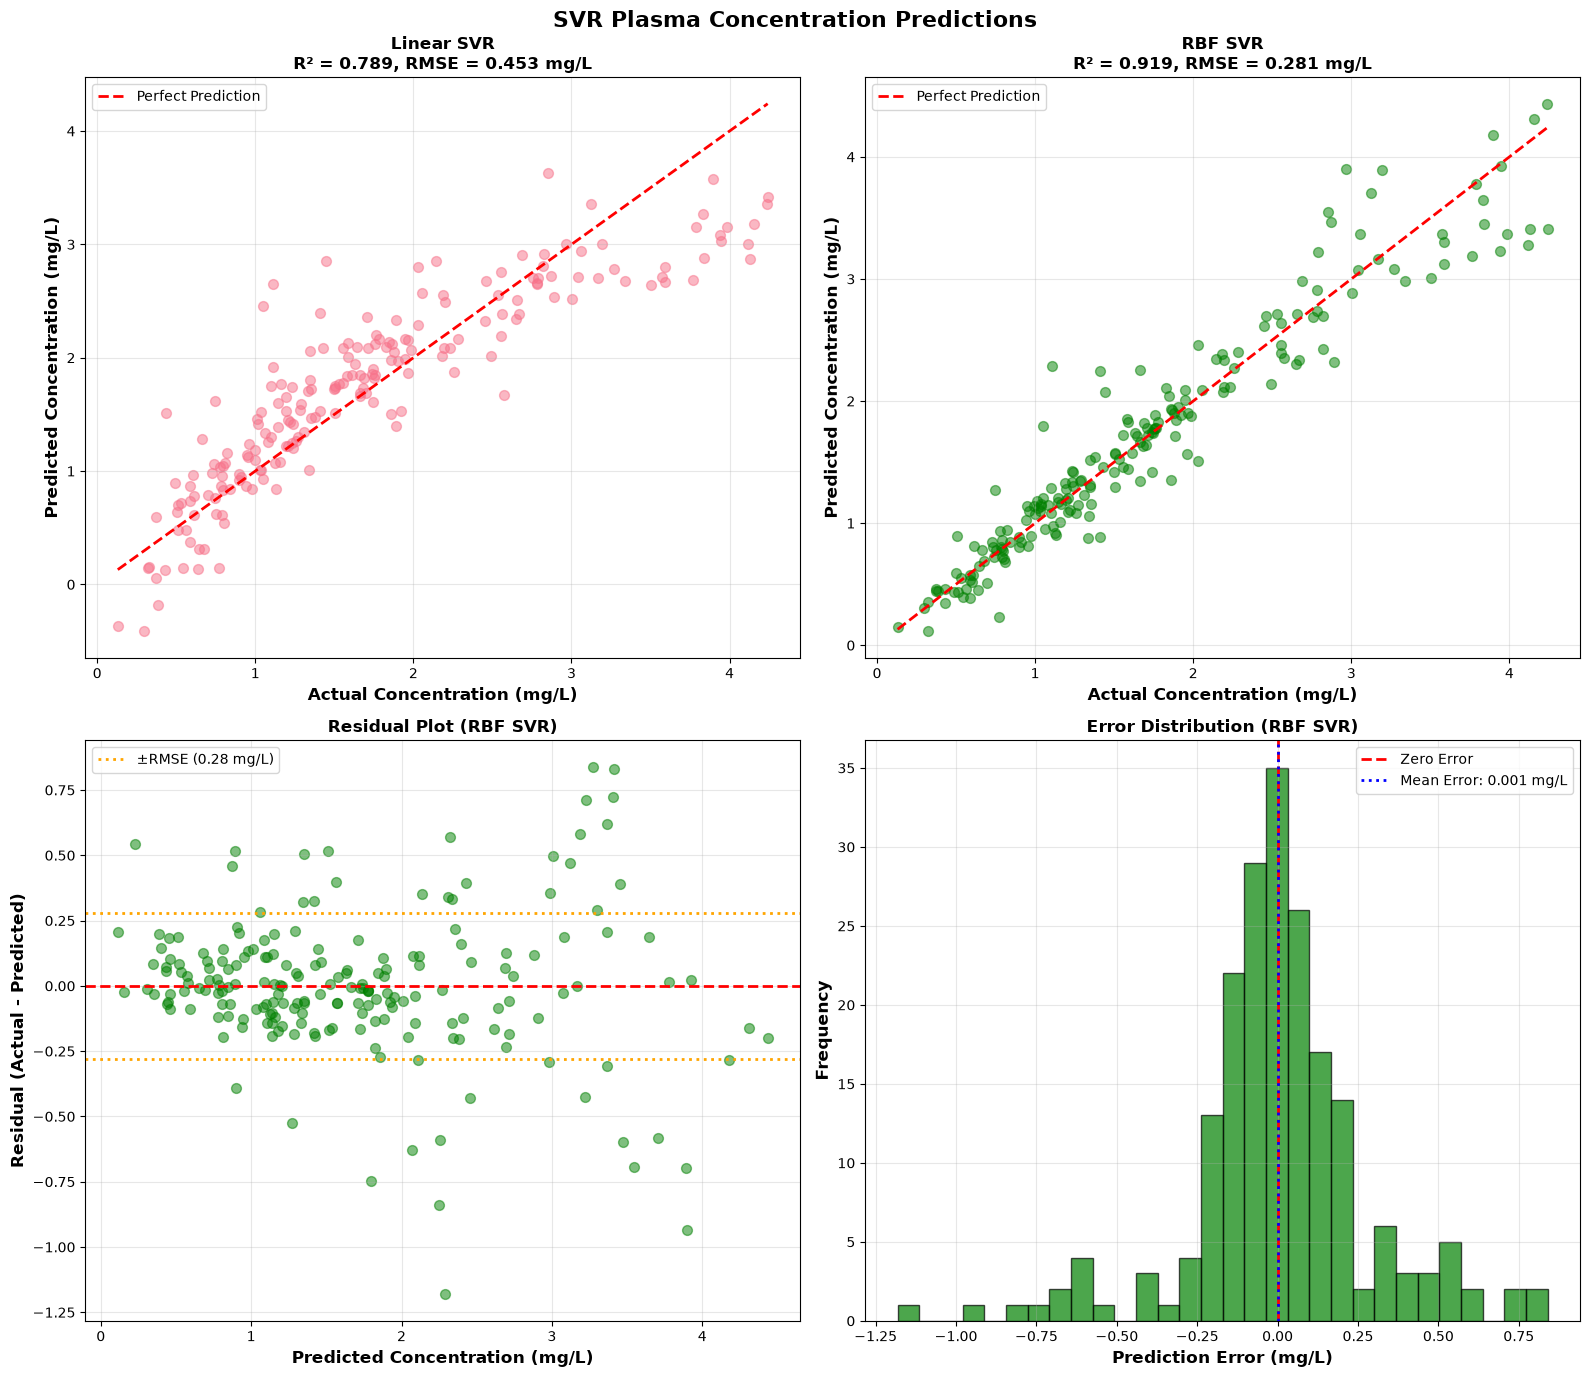


🔍 Prediction Quality Assessment:
   • RBF model explains 91.9% of concentration variance
   • Typical error: ±0.28 mg/L
   • Errors centered near zero (unbiased)
   • Good enough to support dose adjustment and sampling-time advice


In [6]:
# Create prediction visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle('SVR Plasma Concentration Predictions', fontsize=16, fontweight='bold')

# Plot 1: Actual vs Predicted (Linear)
ax = axes[0, 0]
ax.scatter(y_test, y_pred_linear_original, alpha=0.5, s=50)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
        'r--', linewidth=2, label='Perfect Prediction')
ax.set_xlabel('Actual Concentration (mg/L)', fontsize=12, fontweight='bold')
ax.set_ylabel('Predicted Concentration (mg/L)', fontsize=12, fontweight='bold')
ax.set_title(f'Linear SVR\nR² = {r2_linear:.3f}, RMSE = {rmse_linear:.3f} mg/L',
            fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Actual vs Predicted (RBF)
ax = axes[0, 1]
ax.scatter(y_test, y_pred_rbf_original, alpha=0.5, s=50, c='green')
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
        'r--', linewidth=2, label='Perfect Prediction')
ax.set_xlabel('Actual Concentration (mg/L)', fontsize=12, fontweight='bold')
ax.set_ylabel('Predicted Concentration (mg/L)', fontsize=12, fontweight='bold')
ax.set_title(f'RBF SVR\nR² = {r2_rbf:.3f}, RMSE = {rmse_rbf:.3f} mg/L',
            fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Residuals (RBF)
ax = axes[1, 0]
residuals = y_test - y_pred_rbf_original
ax.scatter(y_pred_rbf_original, residuals, alpha=0.5, s=50, c='green')
ax.axhline(y=0, color='r', linestyle='--', linewidth=2)
ax.axhline(y=rmse_rbf, color='orange', linestyle=':', linewidth=2, label=f'±RMSE ({rmse_rbf:.2f} mg/L)')
ax.axhline(y=-rmse_rbf, color='orange', linestyle=':', linewidth=2)
ax.set_xlabel('Predicted Concentration (mg/L)', fontsize=12, fontweight='bold')
ax.set_ylabel('Residual (Actual - Predicted)', fontsize=12, fontweight='bold')
ax.set_title('Residual Plot (RBF SVR)', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Error Distribution
ax = axes[1, 1]
ax.hist(residuals, bins=30, alpha=0.7, color='green', edgecolor='black')
ax.axvline(x=0, color='r', linestyle='--', linewidth=2, label='Zero Error')
ax.axvline(x=residuals.mean(), color='blue', linestyle=':', linewidth=2,
          label=f'Mean Error: {residuals.mean():.3f} mg/L')
ax.set_xlabel('Prediction Error (mg/L)', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('Error Distribution (RBF SVR)', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n🔍 Prediction Quality Assessment:")
print(f"   • RBF model explains {r2_rbf*100:.1f}% of concentration variance")
print(f"   • Typical error: ±{rmse_rbf:.2f} mg/L")
print(f"   • Errors centered near zero (unbiased)")
print(f"   • Good enough to support dose adjustment and sampling-time advice")


## 6. Hyperparameter Tuning for SVR

Let's optimize C, epsilon, and gamma parameters.

In [7]:
print("🔧 SVR Hyperparameter Tuning")
print("=" * 70)

# Define parameter grid
param_grid = {
    'C': [1, 10, 100, 1000],
    'epsilon': [0.01, 0.1, 0.5],
    'gamma': ['scale', 0.001, 0.01, 0.1]
}

print(f"Testing {len(param_grid['C']) * len(param_grid['epsilon']) * len(param_grid['gamma'])} combinations...\n")

# Grid search
grid_search = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=5, 
                           scoring='neg_mean_squared_error', verbose=1, n_jobs=-1)
grid_search.fit(X_train_scaled, y_train_scaled)

print("\n✅ Optimization Complete!")
print("\n🏆 Best Parameters:")
print(f"   C: {grid_search.best_params_['C']}")
print(f"   Epsilon: {grid_search.best_params_['epsilon']}")
print(f"   Gamma: {grid_search.best_params_['gamma']}")
print(f"   Best CV MSE: {-grid_search.best_score_:.3f}")

# Train optimized model
best_svr = grid_search.best_estimator_
y_pred_best = best_svr.predict(X_test_scaled)
y_pred_best_original = scaler_y.inverse_transform(y_pred_best.reshape(-1, 1)).flatten()

rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best_original))
mae_best = mean_absolute_error(y_test, y_pred_best_original)
r2_best = r2_score(y_test, y_pred_best_original)

print(f"\n🎯 Optimized Model Performance:")
print(f"   RMSE: {rmse_best:.3f} mg/L")
print(f"   MAE:  {mae_best:.3f} mg/L")
print(f"   R²:   {r2_best:.3f}")
print(f"   Support Vectors: {len(best_svr.support_)} / {len(X_train)} ({len(best_svr.support_)/len(X_train)*100:.1f}%)")

print("\n💡 Improvement Analysis:")
print(f"   RMSE improved: {rmse_rbf:.3f} → {rmse_best:.3f} mg/L")
print(f"   R² improved: {r2_rbf:.3f} → {r2_best:.3f}")
print(f"   {'✓ Significant improvement!' if r2_best > r2_rbf + 0.01 else '≈ Marginal improvement'}")

🔧 SVR Hyperparameter Tuning
Testing 48 combinations...

Fitting 5 folds for each of 48 candidates, totalling 240 fits



✅ Optimization Complete!

🏆 Best Parameters:
   C: 10
   Epsilon: 0.1
   Gamma: 0.1
   Best CV MSE: 0.059

🎯 Optimized Model Performance:
   RMSE: 0.269 mg/L
   MAE:  0.158 mg/L
   R²:   0.926
   Support Vectors: 402 / 800 (50.2%)

💡 Improvement Analysis:
   RMSE improved: 0.281 → 0.269 mg/L
   R² improved: 0.919 → 0.926
   ≈ Marginal improvement


## 7. Real-World Concentration Prediction

Let's use our optimized SVR to predict concentrations for specific patients.


💊 PLASMA CONCENTRATION PREDICTION EXAMPLES

📍 Scenario 1: Peak Sample - Healthy Adult
   Time since dose: 3 hours
   Age: 35 years
   Weight: 75 kg
   eGFR: 100 mL/min/1.73m2
   Dose: 200 mg
   ➜ Predicted Concentration: 2.43 mg/L
   → Near the expected peak; normal clearance

📍 Scenario 2: Trough Sample - Older Patient, Reduced Renal Function
   Time since dose: 12 hours
   Age: 78 years
   Weight: 62 kg
   eGFR: 35 mL/min/1.73m2
   Dose: 200 mg
   ➜ Predicted Concentration: 2.45 mg/L
   → Impaired clearance keeps the trough high - accumulation risk

📍 Scenario 3: Early Sample - Absorption Phase
   Time since dose: 1 hour
   Age: 55 years
   Weight: 95 kg
   eGFR: 85 mL/min/1.73m2
   Dose: 300 mg
   ➜ Predicted Concentration: 3.12 mg/L
   → Still climbing; a sample this early under-reads the true exposure


📊 Generating Concentration-Time Profile...


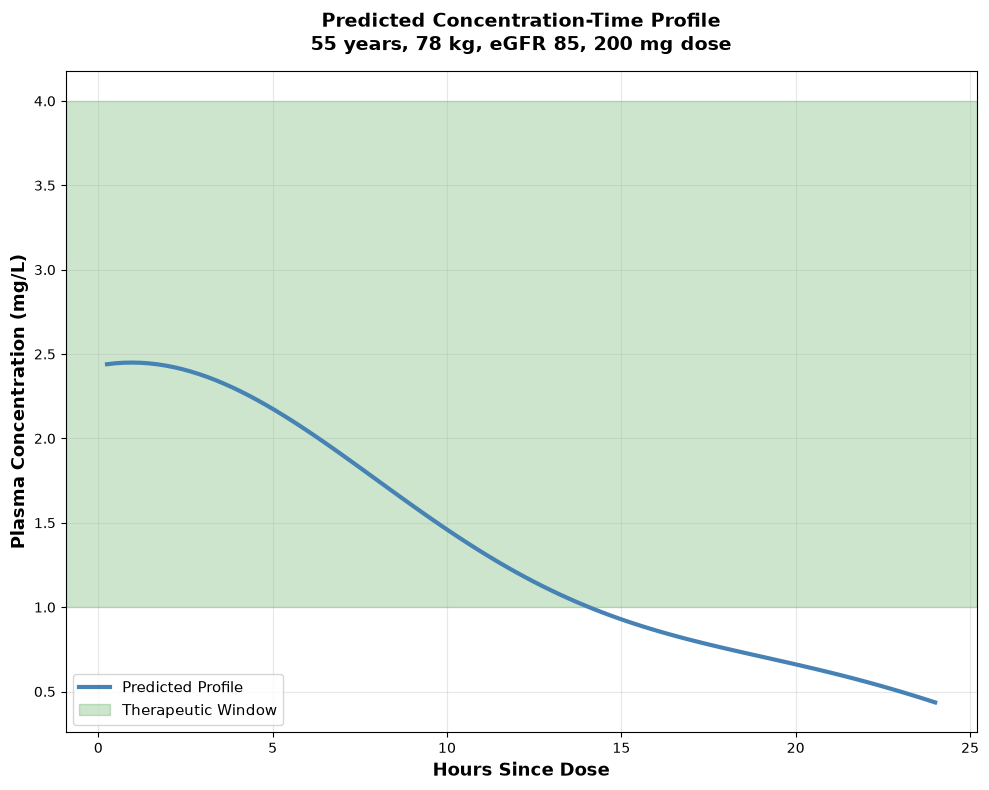


💡 Applications:
   ✓ Therapeutic drug monitoring and dose individualization
   ✓ Choosing when to draw a peak or trough sample
   ✓ Renal dose adjustment for patients with a low eGFR
   ✓ Flagging patients at risk of toxic accumulation


In [8]:
def predict_plasma_concentration(model, scaler_X, scaler_y, hours, age, weight, egfr, dose):
    """
    Predict plasma concentration for a given patient and sampling time.
    """
    # Create input array
    features = np.array([[hours, age, weight, egfr, dose]])

    # Scale and predict
    features_scaled = scaler_X.transform(features)
    conc_pred_scaled = model.predict(features_scaled)
    conc_pred = scaler_y.inverse_transform(conc_pred_scaled.reshape(-1, 1))[0, 0]

    return conc_pred

print("💊 PLASMA CONCENTRATION PREDICTION EXAMPLES")
print("=" * 70)

# Scenario 1: Peak sampling in a healthy adult
print("\n📍 Scenario 1: Peak Sample - Healthy Adult")
print("   Time since dose: 3 hours")
print("   Age: 35 years")
print("   Weight: 75 kg")
print("   eGFR: 100 mL/min/1.73m2")
print("   Dose: 200 mg")
conc1 = predict_plasma_concentration(best_svr, scaler_X, scaler_y, 3, 35, 75, 100, 200)
print(f"   ➜ Predicted Concentration: {conc1:.2f} mg/L")
print("   → Near the expected peak; normal clearance")

# Scenario 2: Trough sampling in an older patient with reduced renal function
print("\n📍 Scenario 2: Trough Sample - Older Patient, Reduced Renal Function")
print("   Time since dose: 12 hours")
print("   Age: 78 years")
print("   Weight: 62 kg")
print("   eGFR: 35 mL/min/1.73m2")
print("   Dose: 200 mg")
conc2 = predict_plasma_concentration(best_svr, scaler_X, scaler_y, 12, 78, 62, 35, 200)
print(f"   ➜ Predicted Concentration: {conc2:.2f} mg/L")
print("   → Impaired clearance keeps the trough high - accumulation risk")

# Scenario 3: Early sample during the absorption phase
print("\n📍 Scenario 3: Early Sample - Absorption Phase")
print("   Time since dose: 1 hour")
print("   Age: 55 years")
print("   Weight: 95 kg")
print("   eGFR: 85 mL/min/1.73m2")
print("   Dose: 300 mg")
conc3 = predict_plasma_concentration(best_svr, scaler_X, scaler_y, 1, 55, 95, 85, 300)
print(f"   ➜ Predicted Concentration: {conc3:.2f} mg/L")
print("   → Still climbing; a sample this early under-reads the true exposure")

# Create concentration-time profile prediction
print("\n\n📊 Generating Concentration-Time Profile...")
profile_hours = np.linspace(0.25, 24, 100)
profile_conc = [predict_plasma_concentration(best_svr, scaler_X, scaler_y, h, 55, 78, 85, 200)
                for h in profile_hours]

plt.figure(figsize=(10, 8))
plt.plot(profile_hours, profile_conc, linewidth=3, color='steelblue', label='Predicted Profile')
plt.xlabel('Hours Since Dose', fontsize=13, fontweight='bold')
plt.ylabel('Plasma Concentration (mg/L)', fontsize=13, fontweight='bold')
plt.title('Predicted Concentration-Time Profile\n55 years, 78 kg, eGFR 85, 200 mg dose',
         fontsize=14, fontweight='bold', pad=15)
plt.grid(True, alpha=0.3)
plt.axhspan(1.0, 4.0, alpha=0.2, color='green', label='Therapeutic Window')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("\n💡 Applications:")
print("   ✓ Therapeutic drug monitoring and dose individualization")
print("   ✓ Choosing when to draw a peak or trough sample")
print("   ✓ Renal dose adjustment for patients with a low eGFR")
print("   ✓ Flagging patients at risk of toxic accumulation")


## 8. SVR vs Other Regression Methods

Let's compare SVR with Linear Regression and Decision Tree Regression.


⚔️  REGRESSION ALGORITHM COMPARISON

        Algorithm  RMSE (mg/L)  MAE (mg/L)       R²
        SVR (RBF)     0.269236    0.157530 0.925512
Linear Regression     0.450485    0.346594 0.791463
    Decision Tree     0.419045    0.258966 0.819555


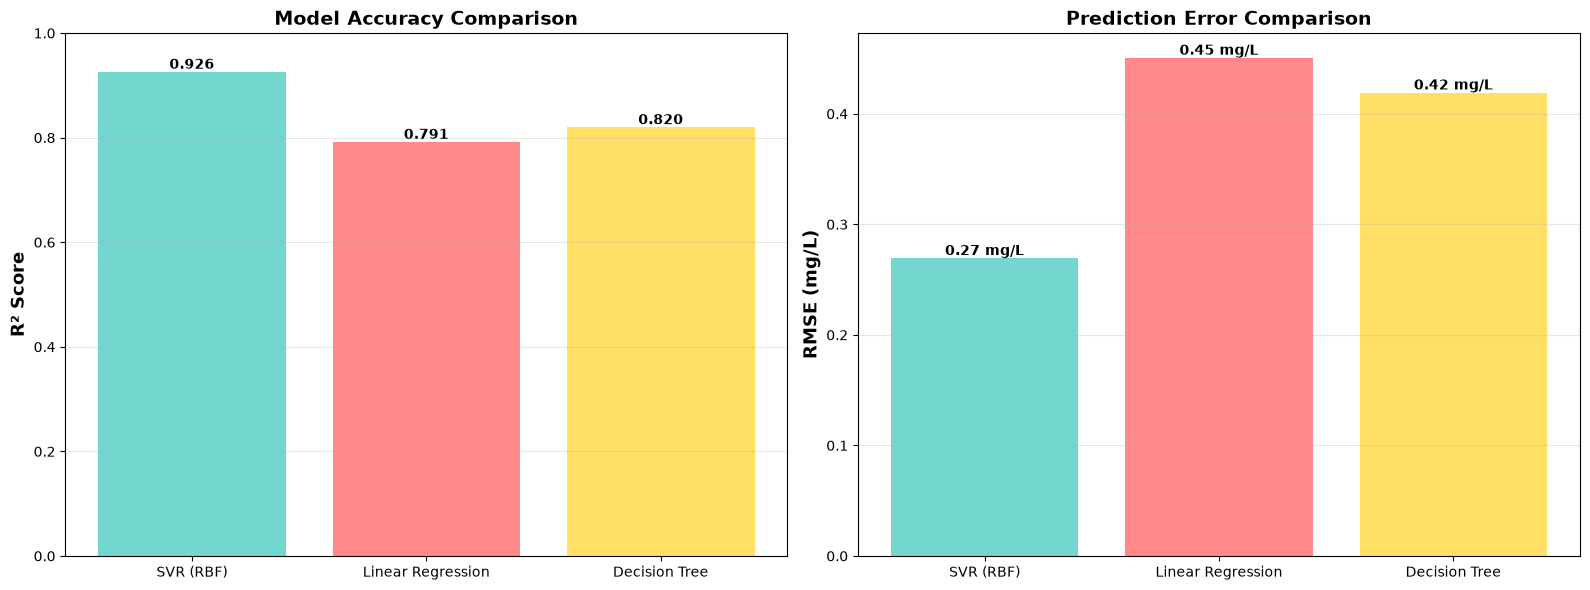



📊 DETAILED COMPARISON

🔵 SUPPORT VECTOR REGRESSION (SVR):
   ✅ Strengths:
      • Excellent for non-linear relationships
      • Robust to outliers (epsilon-tube)
      • Works well in high dimensions
      • Memory efficient (support vectors only)
   ❌ Weaknesses:
      • Slow on large datasets
      • Requires hyperparameter tuning
      • Needs feature scaling

🔴 LINEAR REGRESSION:
   ✅ Strengths: Simple, fast, interpretable
   ❌ Weaknesses: Only captures linear relationships

🟡 DECISION TREE:
   ✅ Strengths: No scaling needed, handles non-linearity
   ❌ Weaknesses: Prone to overfitting, unstable


🩺 CLINICAL RECOMMENDATION:
Use SVR for:
   ✓ Plasma concentration and exposure prediction
   ✓ Renal and hepatic dose adjustment
   ✓ Continuous risk scores from bedside observations
   ✓ Laboratory value forecasting
   ✓ Dose-response modelling


In [9]:
print("⚔️  REGRESSION ALGORITHM COMPARISON")
print("=" * 70)

# Train models
models = {
    'SVR (RBF)': best_svr,
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42)
}

results = []

for name, model in models.items():
    if name != 'SVR (RBF)':  # SVR already trained
        if 'SVR' in name or 'Linear' in name:
            model.fit(X_train_scaled, y_train_scaled)
            y_pred = model.predict(X_test_scaled)
            y_pred_orig = scaler_y.inverse_transform(y_pred.reshape(-1, 1)).flatten()
        else:
            model.fit(X_train, y_train)
            y_pred_orig = model.predict(X_test)
    else:
        y_pred_orig = y_pred_best_original

    # Calculate metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_orig))
    mae = mean_absolute_error(y_test, y_pred_orig)
    r2 = r2_score(y_test, y_pred_orig)

    results.append({
        'Algorithm': name,
        'RMSE (mg/L)': rmse,
        'MAE (mg/L)': mae,
        'R²': r2
    })

# Display results
results_df = pd.DataFrame(results)
print("\n" + results_df.to_string(index=False))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# R2 comparison
ax = axes[0]
bars = ax.bar(results_df['Algorithm'], results_df['R²'], alpha=0.8,
              color=['#4ECDC4', '#FF6B6B', '#FFD93D'])
ax.set_ylabel('R² Score', fontsize=13, fontweight='bold')
ax.set_title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
ax.set_ylim([0, 1.0])
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.3f}', ha='center', va='bottom', fontweight='bold')

# RMSE comparison
ax = axes[1]
bars = ax.bar(results_df['Algorithm'], results_df['RMSE (mg/L)'], alpha=0.8,
              color=['#4ECDC4', '#FF6B6B', '#FFD93D'])
ax.set_ylabel('RMSE (mg/L)', fontsize=13, fontweight='bold')
ax.set_title('Prediction Error Comparison', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.2f} mg/L', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n\n📊 DETAILED COMPARISON")
print("=" * 70)

print("\n🔵 SUPPORT VECTOR REGRESSION (SVR):")
print("   ✅ Strengths:")
print("      • Excellent for non-linear relationships")
print("      • Robust to outliers (epsilon-tube)")
print("      • Works well in high dimensions")
print("      • Memory efficient (support vectors only)")
print("   ❌ Weaknesses:")
print("      • Slow on large datasets")
print("      • Requires hyperparameter tuning")
print("      • Needs feature scaling")

print("\n🔴 LINEAR REGRESSION:")
print("   ✅ Strengths: Simple, fast, interpretable")
print("   ❌ Weaknesses: Only captures linear relationships")

print("\n🟡 DECISION TREE:")
print("   ✅ Strengths: No scaling needed, handles non-linearity")
print("   ❌ Weaknesses: Prone to overfitting, unstable")

print("\n\n🩺 CLINICAL RECOMMENDATION:")
print("=" * 70)
print("Use SVR for:")
print("   ✓ Plasma concentration and exposure prediction")
print("   ✓ Renal and hepatic dose adjustment")
print("   ✓ Continuous risk scores from bedside observations")
print("   ✓ Laboratory value forecasting")
print("   ✓ Dose-response modelling")


## 9. Summary: SVR for Clinical Regression

### ✅ What We've Learned

**Support Vector Regression Concepts:**
- **Epsilon-Tube**: Tolerance zone around predictions
- **Support Vectors**: Points outside the tube
- **Kernel Functions**: Handle non-linear relationships
- **Hyperparameters**: C, epsilon, and gamma

**Strengths for Clinical Applications:**
- ✅ Excellent for complex pharmacokinetic relationships
- ✅ Robust to assay outliers and mis-recorded sampling times
- ✅ Works well with multi-dimensional patient data
- ✅ Memory efficient for deployment
- ✅ Strong performance on medium-sized datasets

**Limitations to Consider:**
- ❌ Slow training on large datasets
- ❌ Requires careful tuning (C, epsilon, gamma)
- ❌ Requires feature scaling
- ❌ Less interpretable than linear models
- ❌ No uncertainty estimates (without modifications)

### 🩺 Clinical Use Cases

**Excellent for:**
- Plasma concentration and drug exposure prediction
- Dose individualization from patient covariates
- Laboratory value forecasting
- Continuous physiological risk scoring
- Dose-response and biomarker modelling

**Not recommended for:**
- Real-time streaming predictions
- Very large datasets (millions of samples)
- Time series forecasting (use specialized methods)
- Cases requiring uncertainty quantification, where a clinician needs a
  confidence interval before changing a dose

### 🎯 Best Practices

1. **Always scale features** (use StandardScaler)
2. **Start with RBF kernel** for most physiological data
3. **Use grid search** for C, epsilon, gamma
4. **Monitor support vector ratio** (<50% ideal)
5. **Validate on held-out test set**
6. **Compare with simpler models** (linear first)

### 📚 Next Steps

- **Ensemble Methods**: Combine multiple models
- **Neural Networks**: Deep learning for complex patterns
- **Gaussian Processes**: For uncertainty quantification
- **Time Series Methods**: LSTM, ARIMA for temporal data

---

*This notebook is part of the Clinical AI Workshop series. You now understand how to apply support vector regression to pharmacokinetic prediction problems!*
